# 2. Inference: single-cell crops through a pretrained image model

Instead of hand-designed features, we can let a neural network look at the images. **OpenPhenom**
([recursionpharma/OpenPhenom](https://huggingface.co/recursionpharma/OpenPhenom)) is a vision transformer trained by
Recursion on millions of Cell Painting images to fill in masked parts of images. Along the way it learns a
384-number **embedding** for each image, which we use as a description of the cell.

The plan: look closely at the data the model will see (the crops in `obsm`, their channel order and how they were
preprocessed), embed cells live on the CPU, check the result against the precomputed embeddings, and then use the
embeddings for biology with mantispy: which compounds change the cells, and do compounds with the same mechanism
look alike? At the end we compare with the hand-designed cp_measure features and a fine-tuned model.

Note: this notebook downloads and runs the model code that Recursion publishes on Hugging Face
(`huggingface_mae.py`); the weights are loaded with `torch.load(..., weights_only=True)`.

In [1]:
TIER = "small"  # or "full"
N_CELLS = 1000  # cells to embed live; None embeds all cells of the tier (about 30 min for the small tier on 4 threads)
RUN_LIVE = False  # True: download OpenPhenom and embed N_CELLS cells live (needs internet, ~2-3 min on 4 threads)

In [2]:
from data import short_warnings

short_warnings()  # warnings stay on, printed without file paths

import os
import sys
import time
from pathlib import Path

import anndata as ad
import mantispy as mt
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.transforms.v2.functional as TF
from huggingface_hub import snapshot_download

from data import fetch, load_cells, load_images, peak_memory_gb, plot_2d, tier_file, umap_2d

RUN_LIVE = (RUN_LIVE or os.environ.get("SBI2_RUN_LIVE") == "1") and os.environ.get("SBI2_SKIP_LIVE") != "1"  # build-machine overrides
torch.set_num_threads(4)
t_start = time.time()
path = tier_file(TIER)
cells = load_cells(path)
images, masks = load_images(path)

## The data a model sees

Notebook 1 showed the table. For an image model, the important part is `obsm`: next to the embeddings it holds
every cell's crop, stored on disk as a 4-dimensional array (cells x channels x height x width) and read lazily, a
few cells at a time.

In [3]:
print("crops:", images.shape, images.dtype, "| masks:", masks.shape, masks.dtype)
print("image channels:", list(cells.uns["image_channels"]), "| mask channels:", list(cells.uns["mask_channels"]))
print("embeddings in obsm:", {k: v.shape for k, v in cells.obsm.items()})

crops: (11244, 5, 96, 96) uint8 | masks: (11244, 2, 96, 96) uint8
image channels: ['DNA', 'AGP', 'ER', 'Mito', 'RNA'] | mask channels: ['nucleus', 'cell']
embeddings in obsm: {'X_openphenom': (11244, 384), 'X_openphenom_ft': (11244, 128), 'X_ae': (11244, 32)}


Before handing images to any pretrained model, check that they look like what the model was trained on. The file
records how the crops were made in `uns["preprocessing"]`:

In [4]:
for key, value in cells.uns["preprocessing"].items():
    print(f"{key:>17}: {value}")

          cell_qc: CP-BG-Bench: kept cells within the 2.5-97.5% quantiles of nucleus area, cytoplasm area and their ratio; this workshop adds obs['qc_fail'] (True for cells with an empty nucleus or cell mask)
    cell_sampling: CP-BG-Bench: up to 50 cells per well (uniform_per_well, seed 42)
    channel_order: obsm['single_cell_images'] channels follow uns['image_channels'] = [DNA, AGP, ER, Mito, RNA]; JUMP's own order is [DNA, ER, RNA, AGP, Mito], Recursion's [DNA, ER, AGP, RNA, Mito, ...]
 cp_measure_input: 224 px crops scaled to [0, 1], masks > 0 as one object each (nucleus, cell)
             crop: 150 px patch centred on the cell, resized to 224 px (CP-BG-Bench); stored here downsampled to 96 px (cv2 INTER_AREA for images, INTER_NEAREST for masks)
        intensity: per field of view and channel, clipped to the 0.1 and 99.9 percentiles and rescaled to uint8 (CP-BG-Bench per_fov_percentile)
 openphenom_input: X_openphenom: 224 px crops resized to 256 px (bilinear, antialias), uint8

In short, for a pretrained model you need to match:

- **Crop size.** The crops were cut as 150 px patches around each cell and resized to 224 px; the file stores them
  at 96 px to stay small. OpenPhenom expects 256 px, so the precomputed embeddings were made from the 224 px crops,
  resized to 256.
- **Intensity scaling.** Each channel of each field of view was clipped to its 0.1 and 99.9 percentiles and scaled
  to 0-255 (8-bit). OpenPhenom takes 8-bit images and normalizes each channel of each image itself; other models
  expect a specific scaling and give poor embeddings if it differs.
- **Quality control.** Skip cells that failed QC (`obs["qc_fail"]`: an empty nucleus or cell mask).
- **Channel order.** Next.

In [5]:
print(cells.obs["qc_fail"].value_counts().rename({False: "pass", True: "fail"}).to_dict())

{'pass': 11165, 'fail': 79}


### Channel order matters

Our crops store the stains as `[DNA, AGP, ER, Mito, RNA]` (see `uns["image_channels"]`). That is not universal:
JUMP's own files use `[DNA, ER, RNA, AGP, Mito]`, and Recursion, who trained OpenPhenom, use
`[DNA, ER, AGP, RNA, Mito, ...]`. A model that expects ER in the second channel and gets AGP there sees a different
cell.

Always remap **by name**, never by position:

ours: ['DNA', 'AGP', 'ER', 'Mito', 'RNA'] -> model: ['DNA', 'ER', 'AGP', 'RNA', 'Mito'] | index permutation: [0, 2, 1, 4, 3]


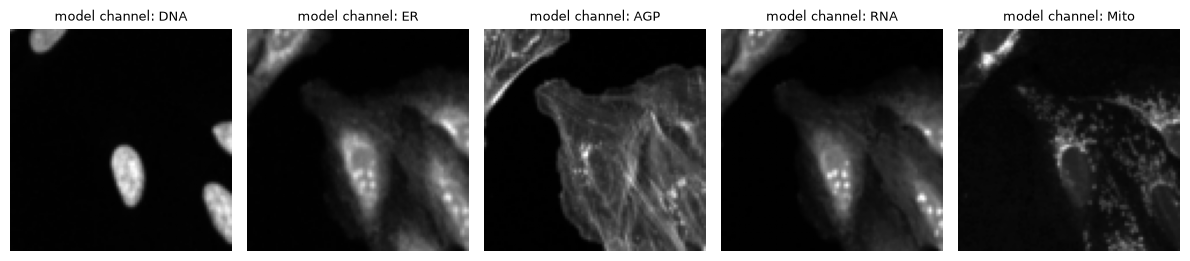

In [6]:
MODEL_ORDER = ["DNA", "ER", "AGP", "RNA", "Mito"]  # Recursion's order, used to train OpenPhenom
ours = list(cells.uns["image_channels"])
perm = [ours.index(name) for name in MODEL_ORDER]
print("ours:", ours, "-> model:", [ours[i] for i in perm], "| index permutation:", perm)

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
crop = np.asarray(images[int(np.flatnonzero(~cells.obs["qc_fail"].to_numpy())[0])])
for ax, i in zip(axes, perm):
    ax.imshow(crop[i], cmap="gray")
    ax.set_title(f"model channel: {ours[i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()

OpenPhenom happens to be **channel-agnostic**: it cuts every channel into 16 x 16 pixel patches, treats all patches
the same way and averages over them, so shuffling the channels does not change its embedding. Many models are not.
SubCell, from the Lundberg lab, is trained on Human Protein Atlas images with a fixed stain layout (a protein of
interest plus reference stains for nucleus, microtubules and ER in fixed slots); there, the wrong order silently
produces meaningless embeddings. Remapping by name is the habit that protects you.

## The model

OpenPhenom is a vision transformer (ViT-S/16) trained as a masked autoencoder. It accepts any number of channels,
expects 256 x 256 pixel images as 8-bit integers, and normalizes each channel of each image itself. We download
Recursion's model code and weights from Hugging Face; the weights are read with `torch.load(..., weights_only=True)`,
which loads tensors only.

In [7]:
if RUN_LIVE:
    snap = Path(snapshot_download("recursionpharma/OpenPhenom", revision="0f92333685f6e9f031b804c70fe246f9b05ae90d"))
    sys.path.insert(0, str(snap.parent))
    op = __import__(f"{snap.name}.huggingface_mae", fromlist=["MAEModel"])
    model = op.MAEModel(op.MAEConfig.from_pretrained(str(snap)))
    with open(snap / "model.safetensors", "rb") as fh:  # despite the name, a regular PyTorch checkpoint
        model.load_state_dict(torch.load(fh, map_location="cpu", weights_only=True)["state_dict"])
    model.eval()
    model.return_channelwise_embeddings = False
    print(f"{sum(p.numel() for p in model.encoder.parameters()) / 1e6:.0f} M encoder parameters")


@torch.inference_mode()
def embed(crops_uint8: np.ndarray, batch_size: int = 32) -> np.ndarray:
    """(n, 5, H, W) uint8 crops in our channel order -> (n, 384) OpenPhenom embeddings."""
    out = []
    for s in range(0, len(crops_uint8), batch_size):
        x = torch.from_numpy(np.ascontiguousarray(crops_uint8[s:s + batch_size][:, perm]))  # remap channels by name
        x = TF.resize(x, [256, 256], antialias=True)  # upsample to the model's input size, still uint8
        out.append(model.predict(x).numpy())
    return np.concatenate(out)

## Inference, live

We embed `N_CELLS` cells that passed QC, reading their 96 px crops from disk and upsampling them to 256 px.

> This copy of the notebook was executed with `RUN_LIVE = False`, so the next three code cells have no output.
> Set `RUN_LIVE = True` at the top to download the model and run them (about 2-3 minutes for 1,000 cells on four
> CPU threads). Everything after them uses the precomputed embeddings and gives the same result either way.

In [8]:
ok = np.flatnonzero(~cells.obs["qc_fail"].to_numpy())
pick = ok if N_CELLS is None else np.sort(np.random.default_rng(0).choice(ok, min(N_CELLS, len(ok)), replace=False))
if RUN_LIVE:
    t0 = time.time()
    live = embed(np.asarray(images[pick]))
    dt = time.time() - t0
    print(f"{len(pick)} cells in {dt:.0f} s = {dt / len(pick) * 1e3:.0f} ms per cell on {torch.get_num_threads()} threads")
    print(f"all {cells.n_obs:,} cells of the {TIER} tier would take about {dt / len(pick) * cells.n_obs / 60:.0f} min; "
          f"the full tier (98,345 cells) about {dt / len(pick) * 98345 / 3600:.1f} h. That is why they were precomputed.")


def cosine(a, b):
    return (a * b).sum(1) / np.linalg.norm(a, axis=1) / np.linalg.norm(b, axis=1)

Do we get the stored embeddings back? The stored ones were computed from the original 224 px crops; we used the
96 px copies, so we expect them to be close but not identical. A small extra file holds 256 cells at 224 px, which
should reproduce the stored numbers exactly.

In [9]:
if RUN_LIVE:
    c96 = cosine(live, cells.obsm["X_openphenom"][pick])
    print(f"96 px crops vs stored:  cosine median {np.median(c96):.3f} (5th percentile {np.percentile(c96, 5):.3f})")
    with h5py.File(fetch("openphenom_demo_crops224.h5"), "r") as f:
        demo = f["images"][:]
        keys = f["row_key"][:].astype(str)
        assert [str(c) for c in f.attrs["channels"]] == ours  # same channel order as the main file
    c224 = cosine(embed(demo), cells.obsm["X_openphenom"][cells.obs_names.get_indexer(keys)])
    print(f"224 px crops vs stored: cosine median {np.median(c224):.4f} (min {c224.min():.4f})")

The 224 px crops reproduce the stored embeddings exactly; the 96 px copies give similar but not identical vectors,
another reminder that preprocessing is part of the model. From here on we use the stored embeddings for all cells,
so the results below are the same whether or not you ran the live part.

## A featurized AnnData

After inference, the natural next step is a new AnnData whose `X` holds the embeddings and whose `obs` is the same
cell metadata. From here on nothing knows or cares that the numbers came from a neural network: every scverse tool
that works on a cells x features matrix (normalization, neighbors, UMAP, clustering, mantispy's profiling metrics)
works on it. This is the hand-off point from deep learning to the rest of the ecosystem.

In [10]:
emb = ad.AnnData(X=np.asarray(cells.obsm["X_openphenom"], dtype=np.float32), obs=cells.obs.copy(),
                 uns={"mantispy": cells.uns["mantispy"]})
emb = emb[~emb.obs["qc_fail"].to_numpy()].copy()
emb

AnnData object with n_obs × n_vars = 11165 × 384
    obs: 'Metadata_Source', 'Metadata_Batch', 'Metadata_Plate', 'Metadata_Well', 'Metadata_Site', 'Metadata_ObjectNumber', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Compound', 'Metadata_InChIKey', 'Metadata_PlateType', 'Metadata_LocalDensity', 'compound', 'target', 'is_control', 'activity_class_selection', 'activity_class', 'selection_map', 'highlight', 'source', 'plate', 'well', 'nuc_area', 'cyto_area', 'nuc_cyto_ratio', 'n_cells_in_fov', 'row_key', 'shard_index', 'key_in_shard', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Row', 'Metadata_Col', 'qc_empty_nucleus', 'qc_empty_cell', 'qc_nan_fraction', 'qc_high_nan', 'qc_tiny_nucleus', 'qc_fail'
    uns: 'mantispy'
    layers: None (.X)

## Biology with mantispy

**Profiles per well.** Single cells are noisy, so profiling works with one profile per well. We put every embedding
dimension on a common scale per plate (a robust z-score against all cells on the plate), then take the median of
the cells in each well (DMSO wells hold only a few cells each, so we keep every well).

In [11]:
mt.pp.normalize(emb, method="mad_robustize", by="Metadata_Plate", reference=None)
wells = mt.tl.aggregate(emb, by=("Metadata_Plate", "Metadata_Well"), func="median", min_cells=1)
wells.obs["is_dmso"] = (wells.obs["Metadata_Perturbation"] == "DMSO").to_numpy()
print(wells)

AnnData object with n_obs × n_vars = 947 × 384
    obs: 'Metadata_Plate', 'Metadata_Well', 'Metadata_CellCount', 'Metadata_SiteCount', 'Metadata_Source', 'Metadata_Batch', 'Metadata_Perturbation', 'Metadata_Perturbation_Type', 'Metadata_Compound', 'Metadata_InChIKey', 'Metadata_PlateType', 'compound', 'target', 'is_control', 'activity_class_selection', 'activity_class', 'selection_map', 'highlight', 'source', 'plate', 'well', 'Metadata_ObjectType', 'Metadata_Control_Type', 'Metadata_Control', 'Metadata_Row', 'Metadata_Col', 'qc_empty_nucleus', 'qc_empty_cell', 'qc_high_nan', 'qc_tiny_nucleus', 'qc_fail', 'is_dmso'
    var: 'degenerate_scale'
    uns: 'mantispy'
    layers: None (.X)


**Which compounds change the cells?** For each compound we ask whether its wells can be told apart from the DMSO
wells of the same source. The score is **mAP** (mean average precision): for every well of the compound, rank all
other wells by similarity and check whether the compound's other wells come before the DMSO wells. mAP is 1 when
they always do and about 0.5 when the compound looks like DMSO; a permutation test gives a q-value, and we call a
compound **active** in a source when q < 0.05. mantispy computes this with `tl.map(mode="activity")`. One source
has a single DMSO well, which is not enough to compare against, so it is skipped.

In [12]:
def activity(wells: ad.AnnData) -> pd.DataFrame:
    rows = []
    for src in sorted(wells.obs["Metadata_Source"].unique()):
        s = wells[wells.obs["Metadata_Source"] == src].copy()
        if s.obs["is_dmso"].sum() < 2:
            continue
        # copairs sees only the Metadata_* columns, so the batch key must be one of them
        mt.tl.map(s, mode="activity", label="Metadata_Perturbation", batch="Metadata_Source", reference="is_dmso",
                  null_size=10_000, n_jobs=4)
        rows.append(s.uns["mantispy"]["map"][["Metadata_Perturbation", "score", "qvalue"]].assign(
            source=src, n_dmso_wells=int(s.obs["is_dmso"].sum())))
    res = pd.concat(rows, ignore_index=True)
    res["active"] = res["qvalue"] < 0.05
    return res


act = activity(wells)
klass = cells.obs.drop_duplicates("compound").set_index("compound")["activity_class"].astype(str)
per_compound = act.groupby("Metadata_Perturbation").agg(mAP=("score", "mean"), active_in=("active", "sum"),
                                                        sources=("source", "nunique"))
per_compound["activity_class"] = per_compound.index.map(klass)
per_compound.sort_values("mAP", ascending=False).round(2).head(15)

,mAP,active_in,sources,activity_class
Metadata_Perturbation,,,,
7-hydroxystaurosporine,1.00,4,4,active
BI-2536,1.00,4,4,active
anisomycin,1.00,4,4,active
NVP-HSP990,1.00,4,4,active
cycloheximide,1.00,4,4,moderate
homoharringtonine,0.99,4,4,active
RGB-286638,0.98,4,4,active
ganetespib,0.98,4,4,active
colchicine,0.98,4,4,active


In [13]:
print("fraction of (compound, source) pairs called active, by activity class:")
act.assign(activity_class=act["Metadata_Perturbation"].map(klass)).groupby("activity_class")["active"].mean().round(2)

fraction of (compound, source) pairs called active, by activity class:


activity_class
active      0.85
inactive    0.13
moderate    0.41
Name: active, dtype: float64

**Do compounds with the same mechanism look alike?** We group the compounds by their annotated targets (from the
JUMP-Target-2 annotation in `obs["target"]`) into a few mechanism classes, average each active compound's wells into
one profile, and ask with `tl.map(mode="consistency")` whether compounds of the same class retrieve each other
better than compounds of other classes.

In [14]:
RULES = [("tubulin", ("TUBA", "TUBB")), ("HSP90", ("HSP90",)), ("ribosome / translation", ("RPL", "RPS")),
         ("CDK", ("CDK",)), ("mitotic kinase (PLK, Aurora)", ("PLK", "AURK")), ("PI3K / mTOR", ("PIK3", "MTOR"))]


def target_class(targets: str) -> str:
    genes = str(targets).split("|")
    for name, prefixes in RULES:
        if any(g.startswith(prefixes) for g in genes):
            return name
    return "other"


targets = cells.obs.drop_duplicates("compound").set_index("compound")["target"].astype(str)
moa = targets.map(target_class)
active_cpds = per_compound.index[(per_compound["active_in"] >= 2) & (per_compound.index != "DMSO")]
cons = wells[wells.obs["Metadata_Perturbation"].isin(active_cpds)]
cons_df = pd.DataFrame(cons.X, index=cons.obs["Metadata_Perturbation"].astype(str).to_numpy()).groupby(level=0).mean()
consensus = ad.AnnData(X=cons_df.to_numpy(np.float32), obs=pd.DataFrame(
    {"Metadata_Perturbation": cons_df.index, "Metadata_MOA": cons_df.index.map(moa)}, index=cons_df.index))
print(consensus.obs["Metadata_MOA"].value_counts().to_dict())

{'other': 12, 'tubulin': 4, 'ribosome / translation': 3, 'mitotic kinase (PLK, Aurora)': 2, 'HSP90': 2, 'PI3K / mTOR': 2, 'CDK': 2}


In [15]:
annotated = consensus[consensus.obs["Metadata_MOA"] != "other"].copy()
mt.tl.map(annotated, mode="consistency", annotation_key="Metadata_MOA", label="Metadata_Perturbation",
          null_size=10_000, n_jobs=4)
annotated.uns["mantispy"]["map"].round(3)

,Metadata_MOA,score,mean_normalized_average_precision,pvalue,qvalue,below_p,is_significant
0,CDK,0.080,-0.198,0.860,0.860,False,False
1,HSP90,1.000,1.000,0.000,0.001,True,True
2,PI3K / mTOR,0.163,-0.090,0.427,0.512,False,False
3,"mitotic kinase (PLK, Aurora)",0.545,0.408,0.070,0.174,False,False
4,ribosome / translation,0.506,0.302,0.153,0.229,False,False
5,tubulin,0.603,0.389,0.087,0.174,False,False


With only two to four compounds per class the test has little power: here only the two HSP90 inhibitors
(ganetespib, NVP-HSP990) retrieve each other significantly. Tubulin binders, translation inhibitors and the mitotic
kinase inhibitors score above chance (mAP 0.5-0.6) without reaching significance, and the CDK and PI3K/mTOR pairs do
not group. A heatmap shows the same thing directly: the similarity between every pair of active compounds, ordered
by hierarchical clustering, with each compound's mechanism class next to its name.

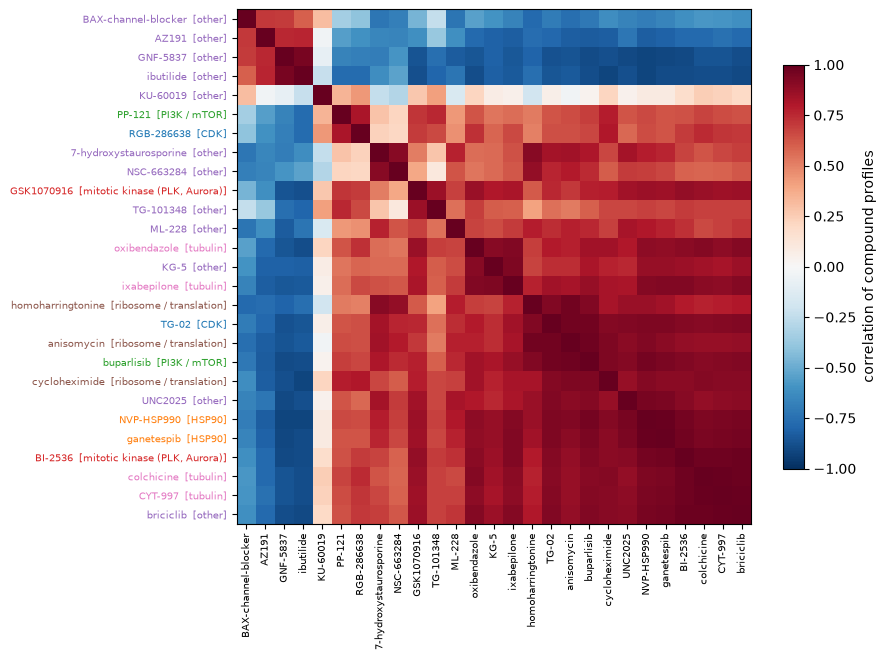

In [16]:
from scipy.cluster.hierarchy import leaves_list, linkage

sim = np.corrcoef(consensus.X)  # Pearson correlation of the centred profiles ~ cosine similarity
order = leaves_list(linkage(consensus.X, "average", metric="cosine"))
names = consensus.obs_names[order]
classes = sorted(set(consensus.obs["Metadata_MOA"]))
palette = dict(zip(classes, plt.get_cmap("tab10").colors))
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7)
ax.set_yticks(range(len(names)), [f"{n}  [{consensus.obs.loc[n, 'Metadata_MOA']}]" for n in names], fontsize=7)
for lab in ax.get_yticklabels():
    lab.set_color(palette[consensus.obs.loc[lab.get_text().split("  [")[0], "Metadata_MOA"]])
plt.colorbar(im, ax=ax, shrink=0.6, label="correlation of compound profiles")
plt.tight_layout()

**A map of the wells**, coloured by mechanism class (active compounds only; "other" in grey covers inactive
compounds and active ones without a class), and a few example crops per class.

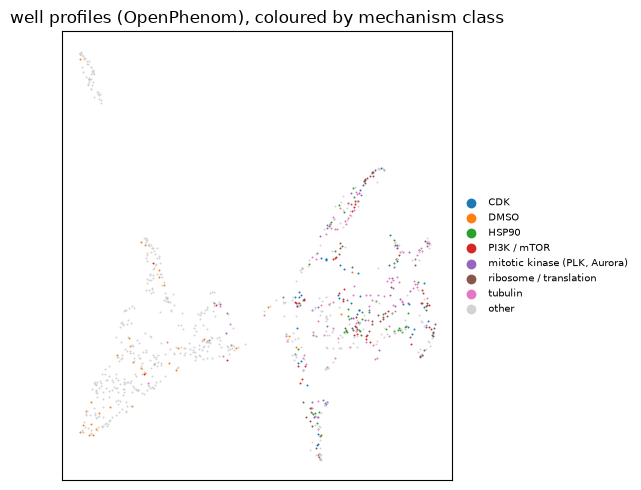

In [17]:
active_set = set(active_cpds)
wells.obs["mechanism"] = ["DMSO" if p == "DMSO" else moa[p] if p in active_set else "other"
                          for p in wells.obs["Metadata_Perturbation"].astype(str)]
xy = umap_2d(wells.X, n_neighbors=10)
plot_2d(xy, wells.obs, ["mechanism"], titles=["well profiles (OpenPhenom), coloured by mechanism class"])
plt.tight_layout()

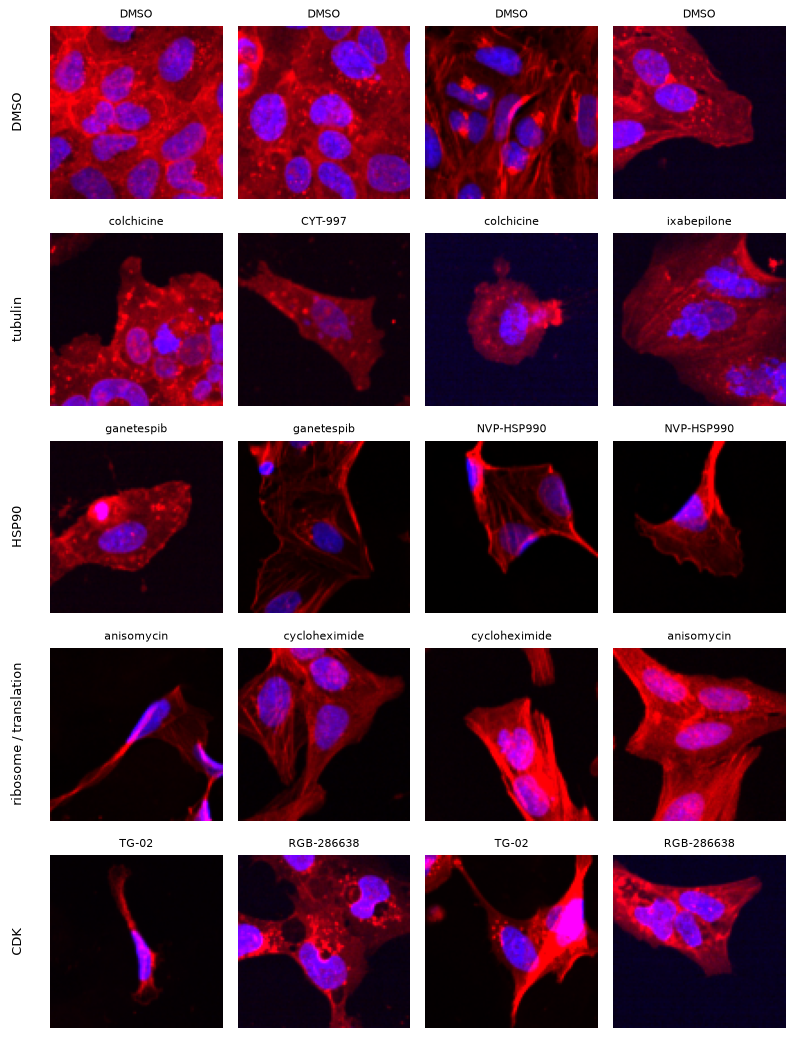

In [18]:
show = [c for c in ["DMSO", "tubulin", "HSP90", "ribosome / translation", "CDK"] if c in set(wells.obs["mechanism"])]
fig, axes = plt.subplots(len(show), 4, figsize=(8, 2.1 * len(show)))
rng = np.random.default_rng(1)
dna, agp = ours.index("DNA"), ours.index("AGP")
for row, name in zip(np.atleast_2d(axes), show):
    cpds = ["DMSO"] if name == "DMSO" else [c for c in active_cpds if moa[c] == name]
    idx = np.flatnonzero(cells.obs["compound"].astype(str).isin(cpds).to_numpy() & ~cells.obs["qc_fail"].to_numpy())
    for ax, i in zip(row, np.sort(rng.choice(idx, 4, replace=False))):
        crop = np.asarray(images[int(i)]).astype(float)
        rgb = np.stack([crop[agp], np.zeros_like(crop[dna]), crop[dna]], -1) / 255  # AGP in red, DNA in blue
        ax.imshow(np.clip(rgb * 1.5, 0, 1))
        ax.set_title(cells.obs["compound"].iloc[int(i)], fontsize=8)
        ax.axis("off")
    row[0].text(-0.15, 0.5, name, transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout()

## The same question with other representations

The file also holds the cp_measure features (`X` of the original object, notebook 1) and a version of OpenPhenom
**fine-tuned in CP-BG-Bench**, a single-cell benchmark on JUMP: in its run 05, a small set of extra weights (LoRA) was
trained on top of OpenPhenom so that images of cells treated with the same compound land close to that compound's
chemical fingerprint (a contrastive, CLIP-style objective). The pretrained model learned what cells look like in
general; the fine-tuned one learned which differences matter for telling compounds apart. We run the same activity
analysis on each.

activity_class,active,moderate,inactive
representation,,,
cp_measure,0.70,0.29,0.00
OpenPhenom,0.85,0.41,0.13
OpenPhenom fine-tuned,0.90,0.39,0.00


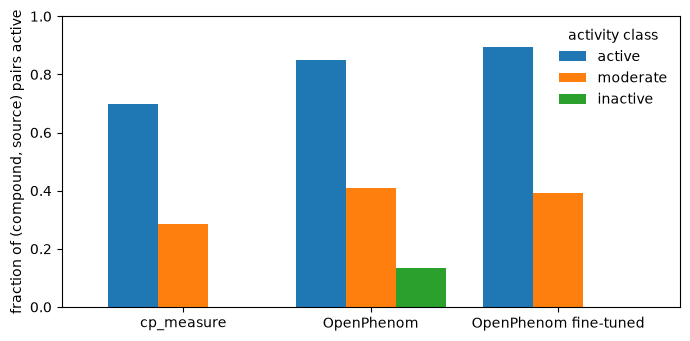

In [19]:
def wells_of(x: np.ndarray, norm: str) -> ad.AnnData:
    """Cells -> normalized, clipped -> median per well. norm: "none" (already normalized), "plate" (all cells of the
    plate as reference) or "dmso_source" (only the DMSO cells of the same source as reference)."""
    a = ad.AnnData(X=np.asarray(x, dtype=np.float32), obs=cells.obs.copy(), uns={"mantispy": cells.uns["mantispy"]})
    a = a[~a.obs["qc_fail"].to_numpy()].copy()
    if norm == "plate":
        mt.pp.normalize(a, method="mad_robustize", by="Metadata_Plate", reference=None)
    elif norm == "dmso_source":
        mt.pp.normalize(a, method="mad_robustize", by="Metadata_Source", reference="negcon")
    a.X = np.clip(np.nan_to_num(a.X), -50, 50)
    w = mt.tl.aggregate(a, by=("Metadata_Plate", "Metadata_Well"), func="median", min_cells=1)
    w.obs["is_dmso"] = (w.obs["Metadata_Perturbation"] == "DMSO").to_numpy()
    return w


sel = cells.var["selected"].to_numpy()
reps = {"cp_measure": activity(wells_of(cells.X[:, sel], "none")),  # X is already normalized per plate
        "OpenPhenom": act,
        "OpenPhenom fine-tuned": activity(wells_of(cells.obsm["X_openphenom_ft"], "plate"))}
res = pd.concat([r.assign(representation=k) for k, r in reps.items()], ignore_index=True)
res["activity_class"] = res["Metadata_Perturbation"].map(klass)
table = res.pivot_table(index="representation", columns="activity_class", values="active", aggfunc="mean")
table = table.loc[list(reps), [c for c in ["active", "moderate", "inactive"] if c in table.columns]]
ax = table.plot.bar(figsize=(7, 3.5), rot=0, width=0.8)
ax.set(ylabel="fraction of (compound, source) pairs active", xlabel="", ylim=(0, 1))
ax.legend(title="activity class", frameon=False)
plt.tight_layout()
table.round(2)

A good representation calls the **active** compounds active and leaves the **inactive** ones alone. (The curated
compounds were picked using the fine-tuned model, so its clean split is partly built in.) All three do well here,
and the image embeddings find more of the active and moderate compounds than the hand-designed features.

### The controls lesson: what you normalize against matters

So far every representation was normalized per plate, against **all** cells on the plate. A common alternative is
to normalize against the negative controls only: subtract the DMSO median and divide by the DMSO spread. That is the
right idea when there are many controls. Here each source has only a handful of DMSO wells (5 to 17), placed at fixed
positions on the plates. Let us redo the cp_measure analysis that way, starting from the raw features in
`layers["raw"]`, and count how often the **inactive** compounds are called active, per source.

In [20]:
reps["cp_measure, vs DMSO per source"] = activity(wells_of(cells.layers["raw"][:, sel], "dmso_source"))
res = pd.concat([r.assign(representation=k) for k, r in reps.items()], ignore_index=True)
res["activity_class"] = res["Metadata_Perturbation"].map(klass)
fp = res[res["activity_class"] == "inactive"].pivot_table(index="representation", columns="source", values="active",
                                                          aggfunc="mean").loc[list(reps)].round(2)
fp.loc["number of DMSO wells"] = res.drop_duplicates("source").set_index("source")["n_dmso_wells"].reindex(fp.columns)
fp

source,source_13,source_5,source_6,source_7
representation,,,,
cp_measure,0.0,0.00,0.0,0.00
OpenPhenom,0.0,0.25,0.0,0.33
OpenPhenom fine-tuned,0.0,0.00,0.0,0.00
"cp_measure, vs DMSO per source",0.0,0.75,0.5,1.00
number of DMSO wells,6.0,17.00,9.0,5.00


The same features, normalized against the few DMSO cells instead of the whole plate, call inactive compounds
active, and how often depends on the source. With so few control wells, the DMSO reference mostly measures where
those wells sit: wells at the plate edge or in one corner differ in temperature, evaporation, cell density and focus,
and hand-designed intensity and texture features pick that up. "Different from DMSO" then partly means "in a
different part of the plate". Using all cells on the plate as the reference averages these position effects out
(it works here because most compounds on a TARGET2 plate do little).

What helps in practice:

- **More controls, spread out.** Dozens of DMSO wells per plate, distributed over the plate, so that position effects
  average out in the reference.
- **Randomized layouts.** Place compounds and controls at random positions (and replicate plates with different
  layouts) so position never lines up with treatment.
- **Batch correction.** Normalize per plate, and correct for plate and source effects (e.g. mantispy's
  `pp.harmony` or a "typical variation normalization" with `pp.tvn`) before comparing to controls.
- **Learned embeddings.** Models trained on many plates and labs learn to ignore much of the technical variation.

In [21]:
print(f"runtime {time.time() - t_start:.0f} s, peak memory {peak_memory_gb():.2f} GB")

runtime 82 s, peak memory 1.58 GB
